# Market Monitoring

How well can a reference-free summary metric tell a platform whose review
summaries have been tampered with from one whose have not?

A **platform** is a sample of 100 product summaries. The monitor scores each one,
takes the platform's mean, and flags the platform when that mean is at or below a
threshold. The question is where to put the threshold, and what the answer costs.

**The threshold is built from clean summaries only.** For each style in the
training folds, its clean products are resampled and platforms simulated from
them; that style's bound is the empirical `ALPHA` quantile of the resulting
platform scores. The fold's threshold is the lowest bound across training
styles. No modified summary enters the fit, which is both what a deployed
monitor could compute and what keeps the detector independent of the attack it
is measured against. One threshold serves every modification on a metric.

**What is assumed:** that a style the monitor has not seen is exchangeable
with the ones it has. Nothing else — no distributional shape, no assumed
prevalence rate, no hyperparameter chosen by looking at results.

**What is measured:** leave-one-out over four axes of shift — style, review
source, product category, review-count group — with every fold's threshold fitted
on the other folds. False positives are measured on the held-out fold's clean
platforms; detection is measured across a prevalence sweep.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def locate_project_root():
    override = os.environ.get("DECEPTION_PROJECT_ROOT")
    if override:
        return Path(override).expanduser().resolve()
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "experiment.yaml").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find experiment.yaml. Start Jupyter inside the project or "
        "set DECEPTION_PROJECT_ROOT."
    )


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from score_analysis import load_config
from score_analysis import (
    CONDITION_LABELS,
    METRIC_LABELS,
    SUMMARY_CONDITION_LABELS,
    load_score_analysis,
    metric_order,
)

# The generated panel only; the hand-written edits are analysed in plot_scores.
SCORES_PATH = PROJECT_ROOT / "data/scores.parquet"
OUTPUT_ROOT = Path(
    os.environ.get(
        "DECEPTION_MARKET_OUTPUT_ROOT",
        PROJECT_ROOT / "results" / "figures" / "market_monitoring",
    )
).expanduser().resolve()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# The shared loader joins scores to the current summaries/modifications files,
# removes superseded score revisions, and exposes the current taxonomy.
score_long = load_score_analysis(project_root=PROJECT_ROOT, score_sets=("main",),
                                 keep_all_judges=True)
score_long = score_long.copy()

# Every G-Eval judge configured in experiment.yaml is evaluated in turn. Rows
# without a judge - the non-G-Eval metrics, which no condition here is scored
# on - are dropped.
_config = load_config(str(PROJECT_ROOT / "experiment.yaml"))
score_long = score_long[score_long["judge"].notna()].copy()
JUDGES = [name for name in _config["geval_judges"] if name in set(score_long["judge"])]

# Lower raw values are more suspicious for every metric; flip them so higher
# means more faithful, without rescaling.
score_long["faithfulness_score"] = -score_long["anomaly_score"]

metadata_columns = [
    "record_id", "product_id", "summary_condition", "source", "category",
    "review_count_bin", "family", "condition",
]
record_metadata = (
    score_long.sort_index()
    .drop_duplicates("record_id", keep="last")[metadata_columns]
)
score_wide = score_long.pivot_table(
    index=["record_id", "judge"],
    columns="metric",
    values="faithfulness_score",
    aggfunc="last",
).reset_index()
score_wide.columns.name = None

df_all = record_metadata.merge(score_wide, on="record_id", how="inner")
df_all["summary_type"] = df_all["summary_condition"]
# The count-1 conditions carry a direction the rest of the taxonomy does not:
# `factual_error_count1_advantageous` and `..._disadvantageous` are one severity
# level split two ways. The original experiments treated that level as a single
# condition, so the two are pooled back into one bias type here and the
# direction stays available in its own column for anyone who wants to split on
# it. Without this the detection cells fit and plot them as two unrelated
# conditions, each on half the modified pool.
df_all["bias_type"] = np.where(
    df_all["family"].eq("faithful"),
    "source",
    df_all["condition"].str.replace(
        r"_count1_(advantageous|disadvantageous)$", "_count1", regex=True
    ),
)
df_all["review_group"] = df_all["review_count_bin"]

# Every scored record, of every judge; the experiment cell takes one judge's
# slice at a time.
df = df_all
DF_ALL_JUDGES = df

AVAILABLE_METRICS = [
    metric for metric in metric_order(score_long)
    if metric in df.columns and df[metric].notna().any()
]
if not AVAILABLE_METRICS:
    raise ValueError("No numeric metric scores are available for market monitoring.")

# The order every table lists the modifications in: the review removals first,
# then the rest alphabetically.
REMOVAL_ORDER = [
    "remove_50pct_one_star", "remove_100pct_one_star",
    "remove_50pct_five_star", "remove_100pct_five_star",
]
present_conditions = set(df.loc[df["bias_type"].ne("source"), "bias_type"].dropna())
AVAILABLE_CONDITIONS = (
    [condition for condition in REMOVAL_ORDER if condition in present_conditions]
    + sorted(present_conditions.difference(REMOVAL_ORDER))
)
AVAILABLE_STYLES = sorted(df["summary_type"].dropna().unique())

CONDITION_PRETTY_LABELS = {
    condition: CONDITION_LABELS.get(condition, condition.replace("_", " ").title())
    for condition in AVAILABLE_CONDITIONS
}
STYLE_LABELS = {
    style: SUMMARY_CONDITION_LABELS.get(style, style.replace("_", " ").title())
    for style in AVAILABLE_STYLES
}
METRIC_PRETTY_LABELS = {
    metric: METRIC_LABELS.get(metric, metric.replace("_", " ").title())
    for metric in AVAILABLE_METRICS
}


## Configuration

In [2]:
# =============================================================================
# CONFIGURATION
#
# Every knob the experiment and the figures share lives here, so the two cannot
# drift apart and there is one place to change a setting.
# =============================================================================

# ─── What to run ─────────────────────────────────────────────────────────────
#
# Which G-Eval metrics, and which judges, the experiment evaluates. None runs
# every one the scores carry; a list runs only those. Every loop below - the
# folds, the deployment threshold, the tables and the figures - reads these, so
# a condition whose metric is left out is simply skipped. The judges are the
# expensive axis: each one repeats the whole experiment.
RUN_METRICS = ["geval_consistency", "geval_relevance"]
RUN_JUDGES = ["qwen36"]          # e.g. ["qwen36"]

for _name, _chosen, _available in (("RUN_METRICS", RUN_METRICS, AVAILABLE_METRICS),
                                   ("RUN_JUDGES", RUN_JUDGES, JUDGES)):
    _unknown = sorted(set(_chosen or []) - set(_available))
    if _unknown:
        raise KeyError(f"{_name} names {_unknown}, not in the scores: {_available}")
METRICS_TO_RUN = [m for m in AVAILABLE_METRICS if RUN_METRICS is None or m in RUN_METRICS]
JUDGES_TO_RUN = [j for j in JUDGES if RUN_JUDGES is None or j in RUN_JUDGES]

# Which modifications the experiment evaluates: by default the ones the figures
# plot. Add any other from AVAILABLE_CONDITIONS to compute it as well (it then
# appears in the tables and, with PLOT_SINGLE_CONDITIONS, gets its own figure),
# or set None to run every one. Leaving one out changes nothing for the rest:
# each condition's seeds depend on its folds and replicates, not on which other
# conditions run.
RUN_CONDITIONS = [
    "factual_error_count1",
    "quantifier_swap_count1",
    "aspect_deletion_count3",
    "remove_100pct_one_star",
    "remove_100pct_five_star",
]

_unknown = sorted(set(RUN_CONDITIONS or []) - set(AVAILABLE_CONDITIONS))
if _unknown:
    raise KeyError(f"RUN_CONDITIONS names {_unknown}, not in the scores: {AVAILABLE_CONDITIONS}")

# ─── Simulation ──────────────────────────────────────────────────────────────

SAMPLES_PER_PLATFORM = 100   # summaries a monitor sees per platform
# Platforms of each kind simulated at every prevalence level: this many
# modified and this many clean.
EVAL_PLATFORMS_PER_CLASS = 1_000
N_BOOTSTRAP          = 100   # product-level bootstrap replicates per fold
RANDOM_STATE         = 42

# Prevalence levels the experiment sweeps.
PREVALENCE_LEVELS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                     15, 20, 25, 30, 35, 40, 50, 60, 70, 80, 90, 100]

# A fold needs enough distinct products for a bootstrap over them to mean
# anything. Some condition/style cells hold almost none: a quantifier swap needs
# quantifiers to swap, and a single-sentence summary has few. Resampling one
# product with replacement returns that product every time, and a fold built
# that way reports a deterministic rate. Folds below this are dropped and named.
MIN_PRODUCTS_PER_FOLD = 25

# ─── The threshold ───────────────────────────────────────────────────────────
#
# One declared budget, and nothing fitted to data that is also reported on.
#
#   ALPHA   how many of a given style's clean platforms may trip the alarm.
#
# A style's bound is the empirical ALPHA quantile of its simulated clean
# platform scores. The fold threshold is the lowest bound among the training
# styles, which under exchangeability leaves an unseen one above it with
# probability n/(n+1) - exactly, with no assumption about the shape of anything.
# Coverage is therefore set by how many styles the corpus has rather than
# by a choice: eleven of them gives 11/12, and reaching 95% would take nineteen.

ALPHA = 0.0

# Platforms simulated per style per replicate. This is Monte Carlo
# resolution for the quantile, not sample size: the statistical sample is the
# products, and raising this sharpens the quantile without narrowing any
# reported interval.
PLATFORM_SIMULATIONS = 10_000
SIMULATION_CHUNK     = 25_000   # simulated in blocks, so memory stays flat

# Clean platforms simulated per fold and replicate for the false-positive rate,
# as many as are simulated of each kind for the TPR.
FALSE_ALARM_PLATFORMS = EVAL_PLATFORMS_PER_CLASS

STYLE_COLUMN        = "summary_type"
MIN_TRAINING_STYLES = 3         # too few to take a minimum over

# ─── What is held out, and what counts as clean ──────────────────────────────

# Rows with this bias_type are the unmodified summaries.
FAITHFUL_LABELS = ["source"]
KNOWN_STYLES = set(AVAILABLE_STYLES)

# Leave-one-out axes for the experiment. "Style" is always the first row of a
# figure and is added by the runner.
ROBUSTNESS_AXES = [("source", "Source"),
                   ("category", "Product Category"),
                   ("review_group", "Review Count Group")]
AXIS_COLUMN_TITLES = {"Style": "Summary Style", "Source": "Review Source",
                      "Product Category": "Product Category",
                      "Review Count Group": "Review Count"}

# Each condition is scored by the metric that can detect it: Consistency for
# factual errors and quantifier swaps, Relevance for aspect deletions and review
# removal.
METRIC_FOR_CONDITION = {
    condition: ("geval_relevance" if condition.startswith(("aspect_deletion", "remove_"))
                else "geval_consistency")
    for condition in AVAILABLE_CONDITIONS
}
METRICS_FOR_CONDITION = {c: [m] for c, m in METRIC_FOR_CONDITION.items()}
CONDITIONS = [c for c in AVAILABLE_CONDITIONS if RUN_CONDITIONS is None or c in RUN_CONDITIONS]

# ─── Figures ─────────────────────────────────────────────────────────────────

# Shaded 95% bootstrap bands behind each curve. Off for figures that go in a
# paper: the spread across held-out folds is the uncertainty that matters, and
# the bands add a second, narrower one on top of it that is easy to misread.
SHOW_CONFIDENCE_BANDS = False

PERF_METRICS = ['recall', 'fpr']
PERF_METRIC_SHORT = {'recall': 'TPR', 'fpr': 'FPR'}
# How a metric is named in a figure title or column header.
METRIC_WORD = {"geval_consistency": "Consistency", "geval_relevance": "Relevance"}
FIGURE_TEXTWIDTH_IN = 7.0

# The combined figure carries one representative condition per error family
# rather than all fourteen, so the five blocks fit in a single row at text
# width. Grouped by metric: consistency first, then relevance.
COMBINED_CONDITIONS = [
    "factual_error_count1",
    "quantifier_swap_count1",
    "aspect_deletion_count3",
    "remove_100pct_one_star",
    "remove_100pct_five_star",
]
COMBINED_BLOCKS_PER_ROW = len(COMBINED_CONDITIONS)

# Spelled out for the combined figure, where there is room for more than the
# abbreviations the per-condition titles use.
# Two lines each: a block is two panels wide, about an inch, and these do not
# fit on one line at a readable size.
COMBINED_CONDITION_LABELS = {
    "factual_error_count1":     "Factual Error\nOne Aspect",
    "quantifier_swap_count1":       "Quantifier Swap\nOne Aspect",
    "aspect_deletion_count3":             "Aspect Deletion\nThree Aspects",
    "remove_100pct_one_star":  "Remove 1-star\nReviews",
    "remove_100pct_five_star": "Remove 5-star\nReviews",
}

COLORS     = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b',
              '#e377c2','#7f7f7f','#bcbd22','#17becf','#ff1493','#00ff00']
MARKERS    = ['o','s','^','v','D','p','*','h','X','P','<','>']
LINESTYLES = ['-','--','-.',':','-','--','-.',':','-','--','-.',':']

# Start from matplotlib's own defaults - black axes of width 0.8, visible tick
# marks, no grid - which is the baseline the figures are designed against. A
# kernel that has run seaborn's set_theme (or any other style) at some point
# carries its rcParams until they are reset, so re-running this cell is enough
# to restore the intended look without restarting.
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 12, 'axes.titlesize': 14, 'axes.labelsize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 10,
    'figure.titlesize': 16, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'figure.dpi': 600,
})


## Simulation primitives

In [3]:
# =============================================================================
# SIMULATION PRIMITIVES
#
# The monitor being simulated: a platform is a sample of summaries, its score
# is the mean of their scores, and it is flagged when that
# score falls below a threshold. The experiment builds the threshold and
# measures the rates through these, so both describe the same monitor.
# =============================================================================

def n_modified(prevalence):
    """Modified summaries on a platform at this prevalence level."""
    return int(SAMPLES_PER_PLATFORM * prevalence / 100.0)


def enough_products(frame):
    """Whether a fold holds enough distinct products to bootstrap over."""
    return frame["product_id"].nunique() >= MIN_PRODUCTS_PER_FOLD


def scores_of(frame, metric):
    """The metric column of a frame as a float array."""
    return frame[metric].to_numpy(dtype=np.float64, copy=True)


def product_pools(frame, metric):
    """One score array per product, the unit a bootstrap replicate redraws."""
    return [scores_of(group, metric) for _, group in frame.groupby("product_id", sort=True)]


def resample_products(pools, rng):
    """Draw len(pools) products with replacement and pool their scores."""
    return np.concatenate([pools[i] for i in rng.integers(0, len(pools), len(pools))])


def platform_scores(matrix):
    """One score per platform (row): the mean score of its summaries."""
    return matrix.mean(axis=1)


def sample_platforms(faithful, modified, n_dec_per, n_platforms, rng):
    """Half modified platforms, half clean ones, with their labels.

    Filled into one preallocated array: the draws, and so the results, are
    identical to stacking the halves, without the extra copies.
    """
    n_pos = n_platforms // 2
    n_neg = n_platforms - n_pos
    n_per = SAMPLES_PER_PLATFORM

    matrix = np.empty((n_platforms, n_per))
    labels = np.zeros(n_platforms, dtype=np.int8)

    if n_dec_per > 0:
        matrix[:n_pos, :n_dec_per] = modified[rng.integers(0, len(modified), (n_pos, n_dec_per))]
        matrix[:n_pos, n_dec_per:] = faithful[rng.integers(0, len(faithful),
                                                           (n_pos, n_per - n_dec_per))]
        labels[:n_pos] = 1
    else:
        matrix[:n_pos] = faithful[rng.integers(0, len(faithful), (n_pos, n_per))]

    matrix[n_pos:] = faithful[rng.integers(0, len(faithful), (n_neg, n_per))]
    return matrix, labels


def detection_rates(faithful, modified, prevalence, threshold, seed):
    """Simulate platforms at this prevalence and return (TPR, FPR)."""
    matrix, labels = sample_platforms(faithful, modified, n_modified(prevalence),
                                      2 * EVAL_PLATFORMS_PER_CLASS,
                                      np.random.default_rng(seed))
    flagged = -platform_scores(matrix) >= threshold
    positive = labels == 1
    return (float(flagged[positive].mean()) if positive.any() else float("nan"),
            float(flagged[~positive].mean()) if (~positive).any() else float("nan"))


## Experiment

In [4]:
# =============================================================================
# THE EXPERIMENT
#
# One pass per condition. For every held-out fold: build a threshold from clean
# summaries alone, freeze it, then measure how often it fires on that fold's
# clean platforms and on platforms modified at each level of the sweep.
#
# Nothing here consults a modified summary until the threshold is already fixed,
# and nothing consults the held-out fold until then either.
# =============================================================================

import json
import zlib


def prepare_data(df, condition, metric):
    """Faithful and modified rows for one condition, on the styles they share."""
    work = df[df['summary_type'].isin(KNOWN_STYLES)].dropna(subset=[metric])

    faithful = work[work['bias_type'].isin(FAITHFUL_LABELS)]
    modified = work[work['bias_type'] == condition]

    shared = set(faithful['summary_type']) & set(modified['summary_type'])
    if not shared:
        return None, None

    return (faithful[faithful['summary_type'].isin(shared)],
            modified[modified['summary_type'].isin(shared)])


def clean_summaries(df, metric):
    """Every clean summary scored on this metric, whatever condition is in play.

    The threshold is built from this rather than from prepare_data's output: a
    monitor's threshold cannot depend on which modification it is facing, so it
    must not depend on which styles that modification could be generated for.
    """
    return df[df['summary_type'].isin(KNOWN_STYLES)
              & df['bias_type'].isin(FAITHFUL_LABELS)].dropna(subset=[metric])


# ─── The threshold ─────────────────────────────────────────────────────────

def style_bound(pools, seed):
    """The ALPHA quantile of one style's clean platform scores.

    `pools` holds that style's clean products. One bootstrap resample of them,
    platforms simulated from the resampled pool, and the quantile read straight
    off the simulated scores - no distribution is assumed or fitted.
    """
    rng = np.random.default_rng(seed)
    panel = resample_products(pools, rng)

    scores, remaining = [], PLATFORM_SIMULATIONS
    while remaining > 0:
        block = min(remaining, SIMULATION_CHUNK)
        matrix = panel[rng.integers(0, len(panel), (block, SAMPLES_PER_PLATFORM))]
        scores.append(platform_scores(matrix))
        remaining -= block

    return float(np.quantile(np.concatenate(scores), ALPHA))


# A style's clean products do not depend on which *style* is held out, so on the
# Style axis the same bounds would otherwise be recomputed for every fold. On
# the other axes the pool does depend on the held-out value, which the key
# records. Seeds derive from the key, so a cached bound is the one that would
# have been computed in place.
_STYLE_BOUND_CACHE = {}


def cached_style_bound(pools, metric, axis_column, held_out, style, replicate):
    key = (metric, axis_column,
           None if axis_column == STYLE_COLUMN else str(held_out),
           str(style), replicate)
    if key not in _STYLE_BOUND_CACHE:
        seed = RANDOM_STATE + zlib.crc32(repr(key).encode()) % 1_000_000
        _STYLE_BOUND_CACHE[key] = style_bound(pools, seed)
    return _STYLE_BOUND_CACHE[key]


_FOLD_THRESHOLD_CACHE = {}


def fold_thresholds(clean_train, metric, axis_column, held_out):
    """One threshold per bootstrap replicate for this fold.

    Per replicate: a bound for each training style, then the lowest of
    them. The lowest because an unseen style sits above the minimum of n
    observed ones with probability n/(n+1) under exchangeability - exact, and
    with no assumption about how the bounds are distributed.

    Identical for every condition sharing a metric and a fold, so it is cached.
    """
    styles = tuple(sorted(set(clean_train[STYLE_COLUMN])))
    key = (metric, axis_column, str(held_out), styles)
    if key in _FOLD_THRESHOLD_CACHE:
        return _FOLD_THRESHOLD_CACHE[key]

    pools_by_style = {style: product_pools(rows, metric)
                      for style, rows in clean_train.groupby(STYLE_COLUMN)}
    pools_by_style = {s: p for s, p in pools_by_style.items() if len(p) >= 2}

    thresholds = []
    for replicate in range(N_BOOTSTRAP):
        bounds = [cached_style_bound(pools, metric, axis_column, held_out, style, replicate)
                  for style, pools in pools_by_style.items()]
        thresholds.append(float(min(bounds)) if len(bounds) >= MIN_TRAINING_STYLES else None)

    _FOLD_THRESHOLD_CACHE[key] = thresholds
    return thresholds


# ─── Leave-one-out evaluation ──────────────────────────────────────────────

def _summarize_bootstrap(boot, prev, metric):
    """Per-replicate arrays → median and 95% interval for one fold and level."""
    thresholds = np.asarray(boot['threshold'])
    out = {"threshold": float(np.median(thresholds)),
           f'{metric}_threshold_lo':     float(np.percentile(thresholds, 2.5)),
           f'{metric}_threshold_hi':     float(np.percentile(thresholds, 97.5)),
           f'{metric}_threshold_median': float(np.median(thresholds))}

    for name in PERF_METRICS:
        arr = np.asarray(boot[name])
        if prev == 0 and name == 'recall':          # undefined: no positives
            out[f'{metric}_{name}'] = out[f'{metric}_{name}_lo'] = \
                out[f'{metric}_{name}_hi'] = np.nan
        else:
            out[f'{metric}_{name}']    = float(np.median(arr))
            out[f'{metric}_{name}_lo'] = float(np.percentile(arr, 2.5))
            out[f'{metric}_{name}_hi'] = float(np.percentile(arr, 97.5))
    return out


def run_leave_one_out_cv(faithful, modified, clean_all,
                         condition, axis_column, axis_label, metric):
    """Hold out each value of one axis; fit on the rest, measure on the held-out.

    Returns one row per fold and prevalence level, or None if every fold was dropped.
    """
    rows = []

    for fold_idx, held_out in enumerate(sorted(faithful[axis_column].unique()), 1):
        train     = clean_all[clean_all[axis_column] != held_out]
        fai_test  = faithful[faithful[axis_column] == held_out]
        mod_test  = modified[modified[axis_column] == held_out]

        if not (enough_products(fai_test) and enough_products(mod_test)):
            print(f"      Fold {fold_idx} ({held_out}): dropped - "
                  f"{fai_test['product_id'].nunique()} clean and "
                  f"{mod_test['product_id'].nunique()} modified products, "
                  f"under the {MIN_PRODUCTS_PER_FOLD} a bootstrap needs.")
            continue

        thresholds = fold_thresholds(train, metric, axis_column, held_out)
        if thresholds[0] is None:
            print(f"      Fold {fold_idx} ({held_out}): fewer than "
                  f"{MIN_TRAINING_STYLES} training styles; fold dropped.")
            continue

        test_pools = (product_pools(fai_test, metric), product_pools(mod_test, metric))

        # One replicate = one threshold plus the panel of test products it is
        # judged on. Pairing them keeps a single source of uncertainty - the
        # finite product pool - flowing through both sides.
        replicates = []
        for b, threshold in enumerate(thresholds):
            seed = RANDOM_STATE + fold_idx * 100_000 + b * 13
            panel = np.random.default_rng(seed + 7717)
            test_fai = resample_products(test_pools[0], panel)
            test_mod = resample_products(test_pools[1], panel)
            # detection_rates compares against the negated platform score.
            replicates.append((seed, -threshold, test_fai, test_mod))

        for prev in PREVALENCE_LEVELS:
            boot = {name: [] for name in PERF_METRICS}
            # Back on the platform-score scale: detection_rates wants the score
            # negated, but a threshold that reads 4.68 belongs in the output as
            # 4.68, matching the per-fold medians beside it.
            boot['threshold'] = [-threshold for _, threshold, _, _ in replicates]
            for seed, threshold, test_fai, test_mod in replicates:
                tpr, fpr = detection_rates(test_fai, test_mod, prev, threshold, seed + 7)
                boot['recall'].append(tpr)
                boot['fpr'].append(fpr)

            row = {"condition": condition, "axis": axis_label, "fold": fold_idx,
                   "held_out": str(held_out), "prevalence": prev, "metric": metric,
                   "n_bootstrap": N_BOOTSTRAP}
            row.update(_summarize_bootstrap(boot, prev, metric))
            rows.append(row)

    return pd.DataFrame(rows) if rows else None


def fold_false_alarms(clean_all, metric):
    """False-positive rate per held-out fold, from every clean summary in it.

    The same for every modification by construction: no modified summary is
    involved, the threshold is the fold's (built from clean summaries alone),
    and the clean test set is all of the fold's clean summaries - not
    prepare_data's, which keeps only the styles a modification could be
    generated for. One value per fold is therefore all there is to report, and
    the figures show it once per metric rather than once per modification.

    Simulated on FALSE_ALARM_PLATFORMS clean platforms per replicate, so the
    rate resolves below the ALPHA budget it is judged against. A platform is
    flagged exactly as in detection_rates: its score at or below the threshold.
    """
    rows = []
    for axis_column, axis_label in [(STYLE_COLUMN, "Style")] + ROBUSTNESS_AXES:
        for held_out in sorted(clean_all[axis_column].dropna().unique()):
            train = clean_all[clean_all[axis_column] != held_out]
            test = clean_all[clean_all[axis_column] == held_out]
            if not enough_products(test):
                continue
            thresholds = fold_thresholds(train, metric, axis_column, held_out)
            if thresholds[0] is None:
                continue

            pools = product_pools(test, metric)
            rates = []
            for replicate, threshold in enumerate(thresholds):
                key = (metric, axis_column, str(held_out), replicate)
                rng = np.random.default_rng(
                    RANDOM_STATE + zlib.crc32(repr(key).encode()) % 1_000_000)
                panel = resample_products(pools, rng)
                flagged, remaining = 0, FALSE_ALARM_PLATFORMS
                while remaining > 0:
                    block = min(remaining, SIMULATION_CHUNK)
                    matrix = panel[rng.integers(0, len(panel), (block, SAMPLES_PER_PLATFORM))]
                    flagged += int((platform_scores(matrix) <= threshold).sum())
                    remaining -= block
                rates.append(flagged / FALSE_ALARM_PLATFORMS)

            rates = np.asarray(rates)
            rows.append({"metric": metric, "axis": axis_label, "held_out": str(held_out),
                         "products": test["product_id"].nunique(),
                         "threshold": float(np.median(thresholds)),
                         "fpr": float(np.median(rates)),
                         "fpr_lo": float(np.percentile(rates, 2.5)),
                         "fpr_hi": float(np.percentile(rates, 97.5))})
    return pd.DataFrame(rows)


def deployment_threshold(clean_all, metric):
    """Per replicate, the lowest per-style bound over every style: the fold rule
    with nothing held out. No modified summary is involved."""
    pools_by_style = {style: product_pools(rows, metric)
                      for style, rows in clean_all.groupby(STYLE_COLUMN)}
    pools_by_style = {s: p for s, p in pools_by_style.items() if len(p) >= 2}

    return np.asarray([
        min(cached_style_bound(pools, metric, "deployment", "all", style, replicate)
            for style, pools in pools_by_style.items())
        for replicate in range(N_BOOTSTRAP)
    ])


def threshold_latex_table(thresholds):
    """The deployment threshold D per metric, as the paper's table prints it."""
    rows = [f"{METRIC_WORD.get(metric, metric)} & {value:.2f} \\\\"
            for metric, value in thresholds.items()]
    quantile = f"{ALPHA * 100:g}\\% quantile" + (", the minimum," if ALPHA == 0 else "")
    caption = ("The deployment thresholds estimated using all faithful data are shown. "
               f"Each threshold uses the empirical {quantile} of the simulated "
               "faithful-platform means for each training summarization style.")
    return "\n".join([
        r"\begin{table}[h!]",
        r"\centering",
        r"\caption{" + caption + "}",
        r"\label{tab:thresholds}",
        r"\begin{tabular}{lc}",
        r"\toprule",
        r"\textbf{G-Eval Metric} & \textbf{Threshold $D$}  \\",
        r"\midrule",
        *rows,
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
    ])


# ─── Run ───────────────────────────────────────────────────────────────────

# One full pass per judge. The caches are keyed by metric, not judge, so they
# are cleared before each pass; the results are kept per judge for the plots.
RESULTS_BY_JUDGE = {}
FALSE_ALARMS_BY_JUDGE = {}

for JUDGE in JUDGES_TO_RUN:
    df = DF_ALL_JUDGES[DF_ALL_JUDGES["judge"].eq(JUDGE)]
    _STYLE_BOUND_CACHE.clear()
    _FOLD_THRESHOLD_CACHE.clear()

    RESULTS_BY_METRIC = {}
    FALSE_ALARMS = {}

    for ACTIVE_METRIC in METRICS_TO_RUN:
        conditions = [c for c in CONDITIONS
                      if ACTIVE_METRIC in METRICS_FOR_CONDITION.get(c, [])]
        if not conditions:
            continue

        clean_all = clean_summaries(df, ACTIVE_METRIC)
        # Once per metric, before any modification is looked at.
        FALSE_ALARMS[ACTIVE_METRIC] = fold_false_alarms(clean_all, ACTIVE_METRIC)

        by_condition = {}
        for condition in conditions:
            faithful, modified = prepare_data(df, condition, ACTIVE_METRIC)
            if faithful is None:
                print(f"{condition}: no summary style carries both clean and modified rows.")
                continue
            frames = [frame for axis_column, axis_label in [(STYLE_COLUMN, "Style")] + ROBUSTNESS_AXES
                      if (frame := run_leave_one_out_cv(faithful, modified, clean_all, condition,
                                                        axis_column, axis_label, ACTIVE_METRIC))
                      is not None]
            if frames:
                by_condition[condition] = frames

        RESULTS_BY_METRIC[ACTIVE_METRIC] = by_condition

    RESULTS_BY_JUDGE[JUDGE] = RESULTS_BY_METRIC
    FALSE_ALARMS_BY_JUDGE[JUDGE] = FALSE_ALARMS

    # The threshold a deployed monitor ships: fitted on everything, nothing held
    # out. The paper's threshold table and the Google Maps case study use it.
    thresholds = {metric: float(np.median(deployment_threshold(clean_summaries(df, metric), metric)))
                  for metric in METRICS_TO_RUN if metric in RESULTS_BY_METRIC}
    table_dir = PROJECT_ROOT / "results" / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    (table_dir / f"thresholds_{JUDGE}.tex").write_text(threshold_latex_table(thresholds) + "\n",
                                                        encoding="utf-8")
    (table_dir / f"thresholds_{JUDGE}.json").write_text(json.dumps(thresholds, indent=2) + "\n",
                                                         encoding="utf-8")
    print(f"Deployment thresholds ({JUDGE}): "
          + ", ".join(f"{metric} {value:.4f}" for metric, value in thresholds.items()))
    print(f"Saved: results/tables/thresholds_{JUDGE}.tex and .json")


Deployment thresholds (qwen36): geval_consistency 4.6450, geval_relevance 4.8050
Saved: results/tables/thresholds_qwen36.tex and .json


## Plots

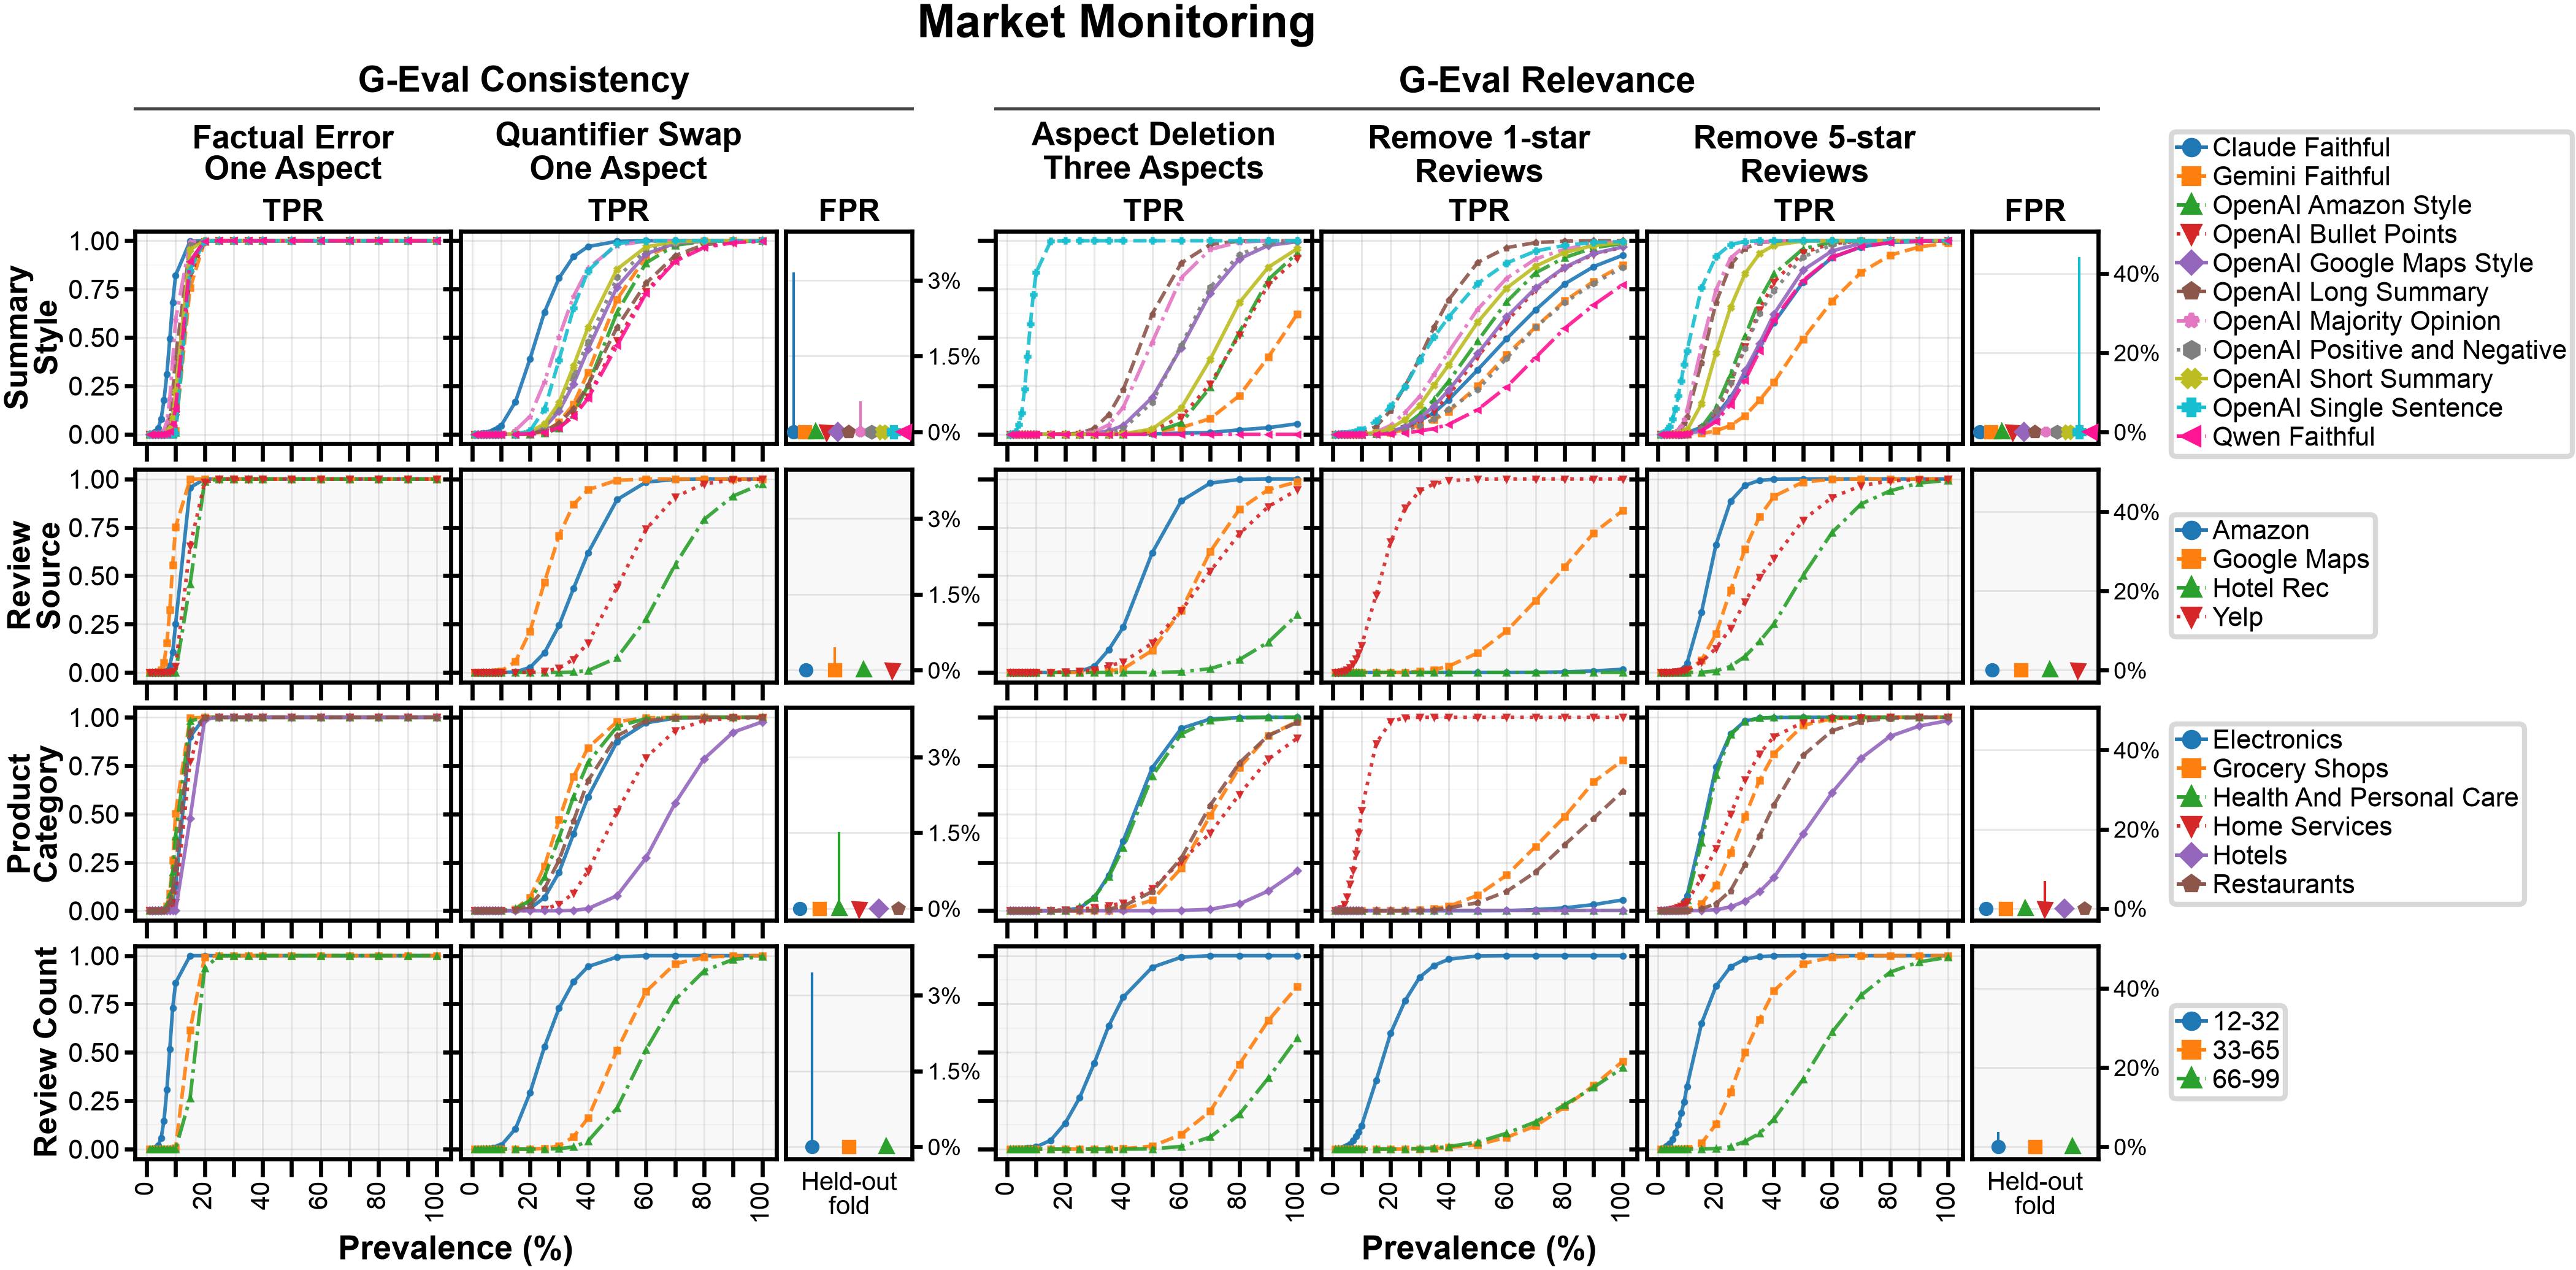

  Saved: results/figures/market_monitoring/market_monitoring_paper_qwen36.pdf


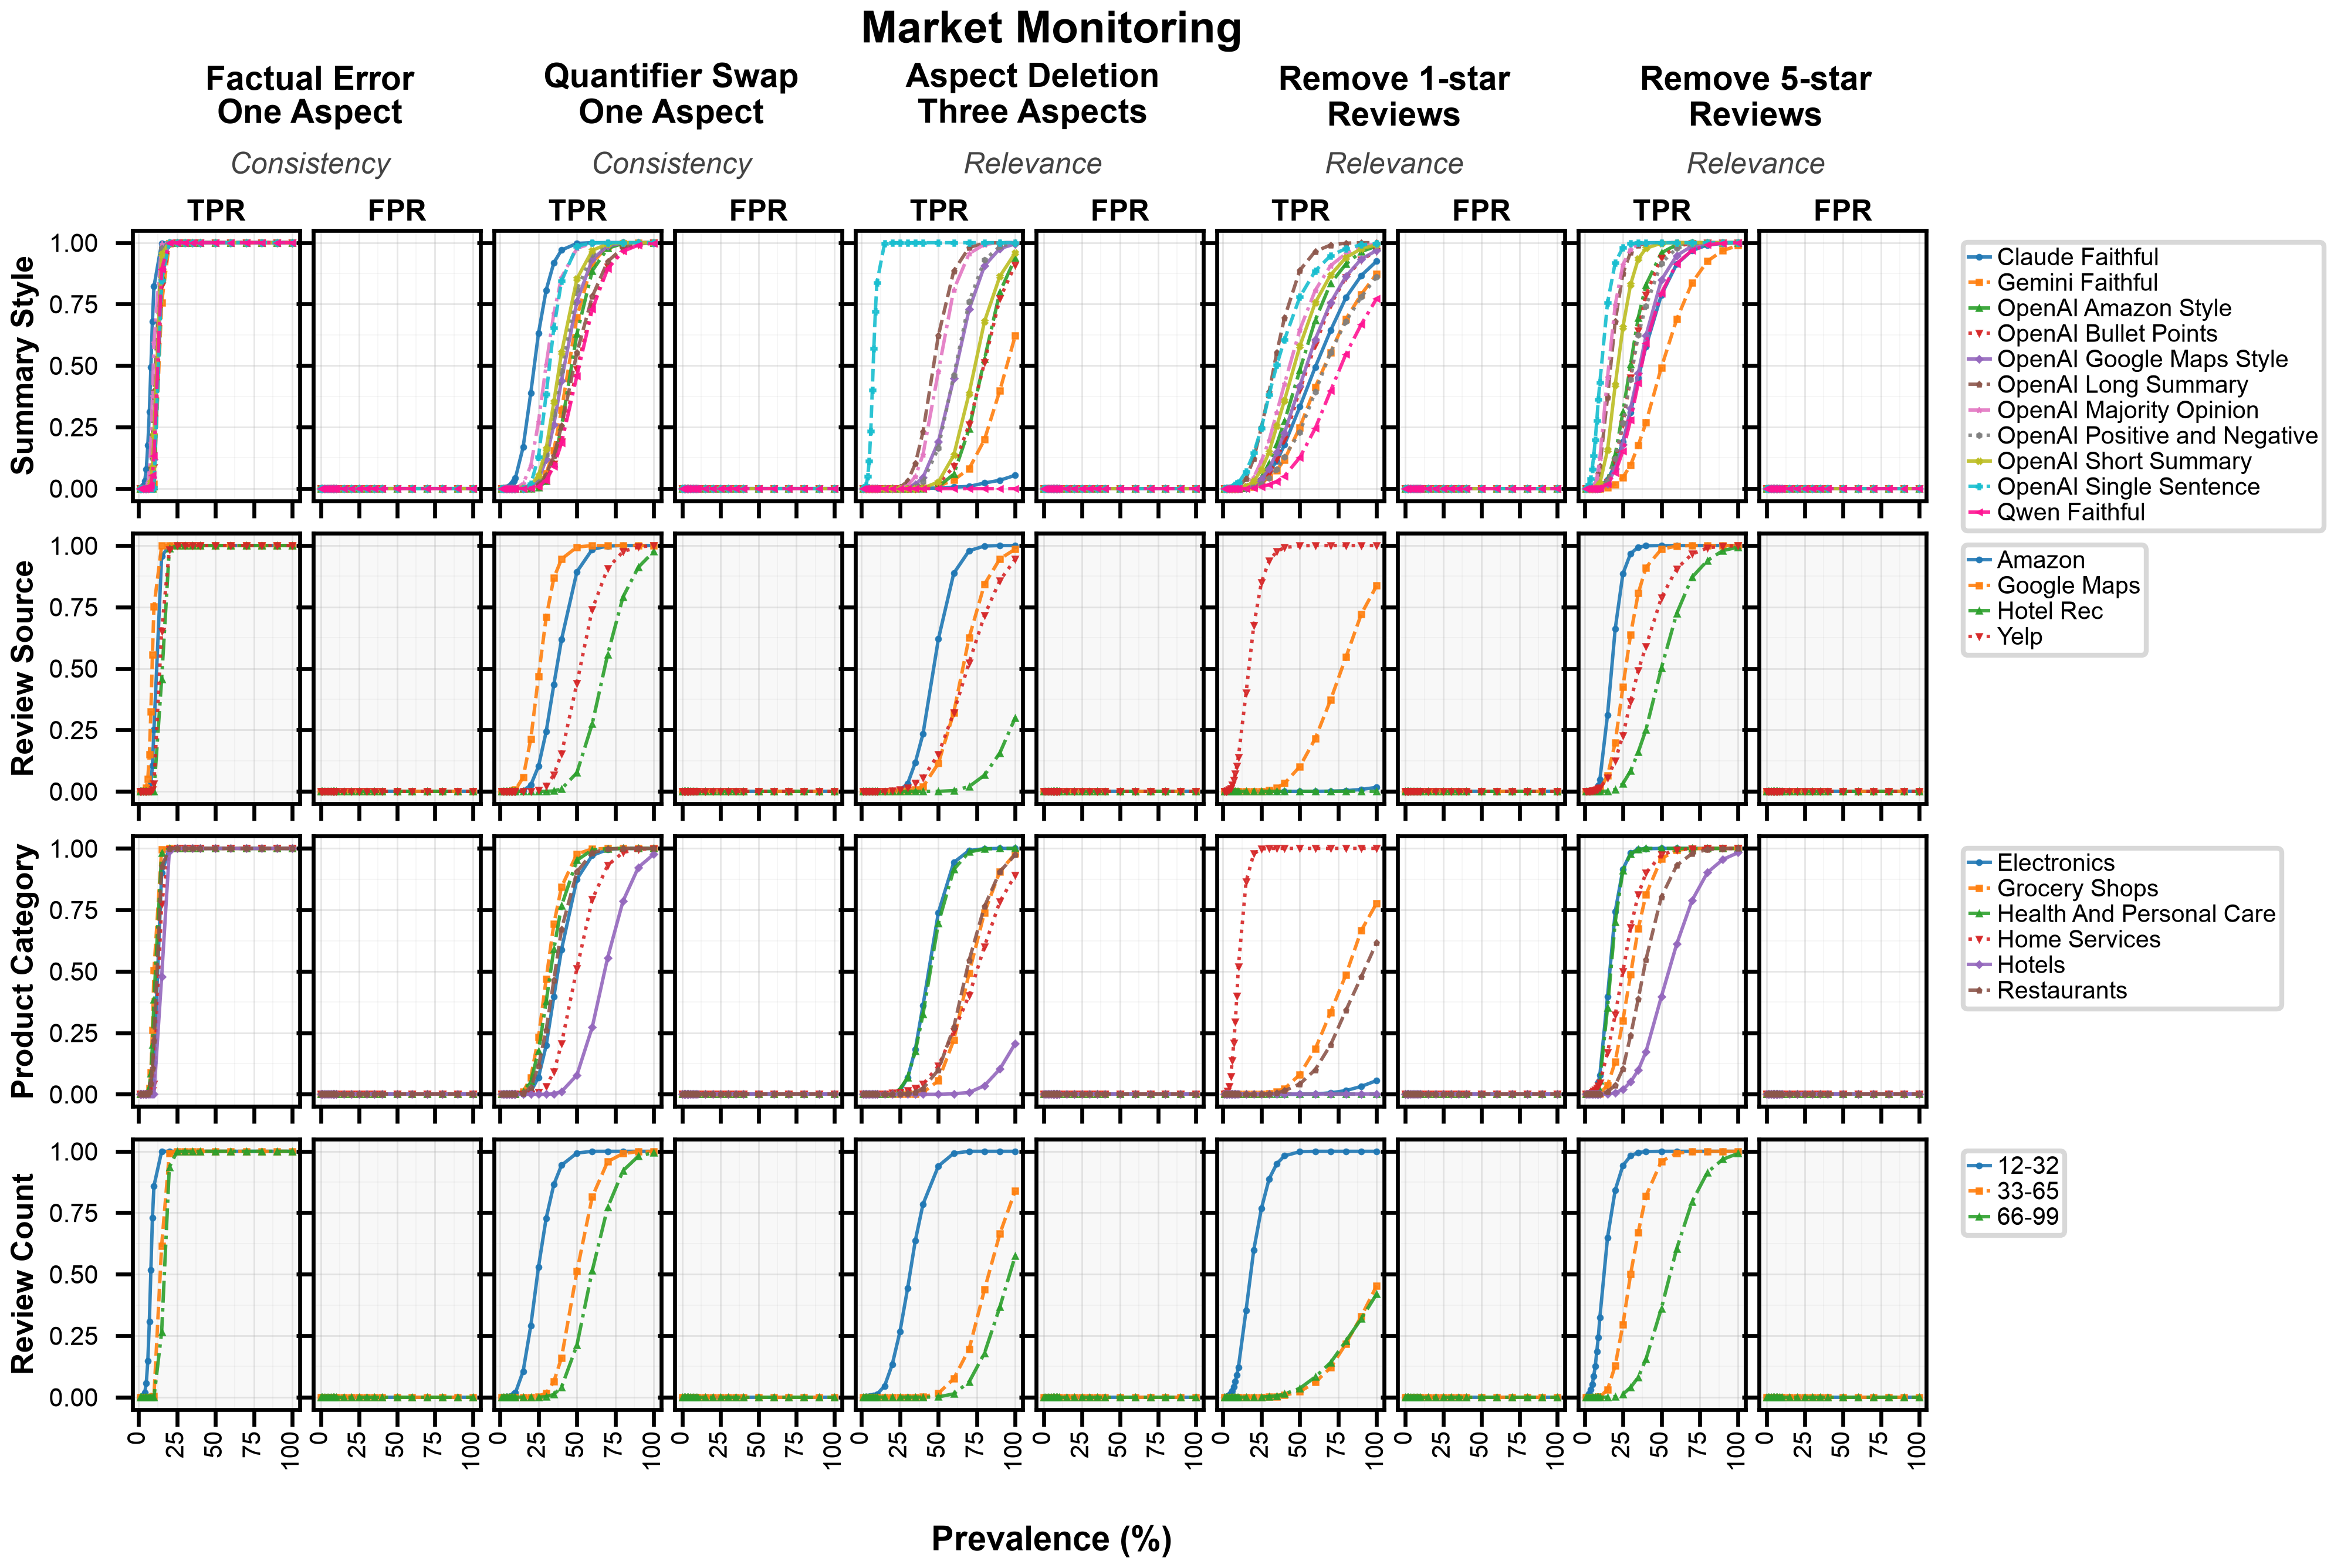

  Saved: results/figures/market_monitoring/market_monitoring_all_conditions_qwen36.pdf


In [5]:
# ─── Market-monitoring figures ─────────────────────────────────────────────
#
# Every figure has one row per robustness axis (summary style, review source,
# product category, review count) and one line or dot per held-out fold.
# Directly under OUTPUT_ROOT, each file name ending in
# the judge so a figure can be told apart once it leaves its folder:
#
#   market_monitoring_paper_<judge>.pdf   paper figure: a TPR panel per
#                                         modification, one FPR panel per metric
#   market_monitoring_all_conditions_<judge>.pdf
#                                         appendix: TPR and FPR per modification
#   <metric>/market_monitoring_<metric>_<condition>_<judge>.pdf
#                                         one figure per modification and metric

import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator

PLOT_GRIDS = True               # the paper figure and the appendix grid
PLOT_SINGLE_CONDITIONS = False  # one figure per modification and metric

AXIS_ORDER = ["Style", "Source", "Product Category", "Review Count Group"]
SHADE = "#f8f8f8"               # background of every second row

CONDITION_LABELS_FOR_FIGURES = {
    "factual_error_count1": "Factual Error (1 Aspect)",
    "factual_error_count2": "Factual Errors (2 Aspects)",
    "factual_error_count3": "Factual Errors (3 Aspects)",
    "factual_error_count4": "Factual Errors (4 Aspects)",
    "aspect_deletion_count1": "Aspect Deletion (1 Aspect)",
    "aspect_deletion_count2": "Aspect Deletions (2 Aspects)",
    "aspect_deletion_count3": "Aspect Deletions (3 Aspects)",
    "aspect_deletion_count4": "Aspect Deletions (4 Aspects)",
    "quantifier_swap_count1": "Quantifier Swap (1 Aspect)",
    "quantifier_swap_count2": "Quantifier Swap (2 Aspects)",
    "quantifier_swap_count3": "Quantifier Swap (3 Aspects)",
    "quantifier_swap_count4": "Quantifier Swap (4 Aspects)",
    "remove_100pct_one_star": "Remove 100% of 1-Star Reviews",
    "remove_100pct_five_star": "Remove 100% of 5-Star Reviews",
}


# ─── Shared helpers ────────────────────────────────────────────────────────

def figure_label(condition):
    """Full name of a modification, for single-condition figure titles."""
    return CONDITION_LABELS_FOR_FIGURES.get(
        condition, CONDITION_PRETTY_LABELS.get(condition, condition.replace("_", " ").title()))


def short_label(condition):
    """Compact name of a modification, for column headers in the grids."""
    return COMBINED_CONDITION_LABELS.get(condition, figure_label(condition))


def fold_label(value, axis_label):
    """How a held-out fold is named in a legend."""
    if axis_label == "Style":
        return STYLE_LABELS.get(str(value), str(value).replace("_", " ").title())
    if axis_label == "Review Count Group":
        return f"{value} reviews"
    return str(value).replace("_", " ").title()


def short_fold_label(value, axis_label):
    return fold_label(value, axis_label).replace(" reviews", "")


def fold_style(i):
    return dict(color=COLORS[i % len(COLORS)], marker=MARKERS[i % len(MARKERS)],
                linestyle=LINESTYLES[i % len(LINESTYLES)])


def frames_by_axis(frames):
    """{robustness axis: results frame}, skipping empty frames."""
    return {f["axis"].iloc[0]: f for f in frames if f is not None and len(f)}


def axes_present(by_axis_dicts):
    """The robustness axes that have data anywhere, in AXIS_ORDER."""
    present = set().union(*by_axis_dicts) if by_axis_dicts else set()
    return [a for a in AXIS_ORDER if a in present]


def save_and_show(fig, path, extra_artists, pad_inches):
    """Save `fig` as a PDF and show the notebook exactly that crop.

    plt.show() would render its own preview with the notebook's 0.1 in padding,
    which is not in the PDF, so the preview is drawn with the same settings.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    settings = dict(bbox_inches="tight", bbox_extra_artists=extra_artists,
                    pad_inches=pad_inches)
    fig.savefig(path, dpi=600, **settings)
    try:
        from IPython.display import Image, display
        preview = io.BytesIO()
        fig.savefig(preview, format="png", dpi=fig.dpi, **settings)
        display(Image(data=preview.getvalue()))
    except ImportError:
        plt.show()
    plt.close(fig)
    print(f"  Saved: {os.path.relpath(path, PROJECT_ROOT)}")


# ─── 1. One figure per modification and metric ─────────────────────────────
# Rows: robustness axes. Columns: the PERF_METRICS (TPR, FPR). Legend per row.

def plot_single_condition(frames, condition, metric, path, width_in=FIGURE_TEXTWIDTH_IN):
    by_axis = frames_by_axis(frames)
    rows = axes_present([by_axis])
    if not rows:
        print(f"  No results for {path}.")
        return

    fig, axes = plt.subplots(
        len(rows), len(PERF_METRICS), figsize=(0.55 * width_in, 0.95 * len(rows) + 0.5),
        sharex="col", sharey=True, squeeze=False,
        gridspec_kw=dict(hspace=0.13, wspace=0.06, top=0.875, bottom=0.13,
                         left=0.085, right=0.78))
    xticks = [p for p in PREVALENCE_LEVELS if p in (0, 20, 40, 60, 80, 100)]

    artists = []
    for r, axis_label in enumerate(rows):
        rdf = by_axis[axis_label]
        for c, perf in enumerate(PERF_METRICS):
            ax = axes[r, c]
            column = f"{rdf['metric'].iloc[0]}_{perf}"
            if column in rdf.columns:
                for i, value in enumerate(sorted(rdf["held_out"].unique())):
                    fold = rdf[rdf["held_out"] == value].sort_values("prevalence")
                    x, y = fold["prevalence"].to_numpy(), fold[column].to_numpy()
                    lo, hi = fold[f"{column}_lo"].to_numpy(), fold[f"{column}_hi"].to_numpy()
                    style = fold_style(i)
                    band = ~(np.isnan(lo) | np.isnan(hi))
                    if SHOW_CONFIDENCE_BANDS and band.any():
                        ax.fill_between(x[band], lo[band], hi[band], color=style["color"],
                                        alpha=0.10, linewidth=0, zorder=2)
                    drawn = ~np.isnan(y)
                    ax.plot(x[drawn], y[drawn], label=fold_label(value, axis_label), **style,
                            markersize=1.8, linewidth=0.8, alpha=0.85, zorder=3,
                            markeredgewidth=0.4)
            else:
                ax.text(0.5, 0.5, "n/a", ha="center", va="center", fontsize=6,
                        color="#999999", transform=ax.transAxes)

            ax.grid(True, linestyle="-", alpha=0.15, zorder=1)
            ax.set_ylim(-0.05, 1.05)
            ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
            if r % 2:
                ax.set_facecolor(SHADE)
            if r == 0:
                ax.set_title(PERF_METRIC_SHORT.get(perf, perf.upper()),
                             fontsize=6.2, fontweight="bold", pad=0.5)
            if c == 0:
                ax.set_ylabel(AXIS_COLUMN_TITLES.get(axis_label, axis_label),
                              fontsize=7, fontweight="bold", labelpad=3)
                ax.tick_params(axis="y", labelsize=5.0)
            else:
                ax.tick_params(axis="y", labelleft=False)
            if r == len(rows) - 1:
                ax.set_xticks(xticks)
                ax.tick_params(axis="x", labelsize=5.0, rotation=45)
            else:
                ax.tick_params(axis="x", labelbottom=False)

        # One legend per row, right of its last panel.
        handles, labels = next(((h, l) for h, l in (a.get_legend_handles_labels()
                                                   for a in axes[r]) if h), ([], []))
        if handles:
            pos = axes[r, -1].get_position()
            legend = fig.legend(handles, labels, loc="center left",
                                bbox_to_anchor=(axes[0, -1].get_position().x1 + 0.008,
                                                (pos.y0 + pos.y1) / 2),
                                bbox_transform=fig.transFigure, fontsize=6.0,
                                framealpha=0.75, borderpad=0.3, handlelength=1.1,
                                handletextpad=0.3, labelspacing=0.2, edgecolor="#cccccc")
            legend.set_in_layout(False)
            artists.append(legend)

    left, right = axes[0, 0].get_position(), axes[0, -1].get_position()
    centre = (left.x0 + right.x1) / 2
    artists += [
        fig.text(centre, 0.905, f"{METRIC_WORD.get(metric, metric)} Metric",
                 ha="center", va="bottom", fontsize=7.0, fontweight="bold"),
        fig.supxlabel("Prevalence (%)", fontsize=7.5, fontweight="bold", x=centre, y=0.05),
        fig.suptitle(f"Market Monitoring: {figure_label(condition)}  "
                     f"(n = {SAMPLES_PER_PLATFORM})",
                     fontweight="bold", fontsize=9.5, x=centre, y=0.995),
    ]
    save_and_show(fig, path, artists, pad_inches=0.03)


# ─── 2. Appendix grid: TPR and FPR for every modification ──────────────────
# Each modification is a block of two columns (TPR, FPR) over the robustness
# axes; blocks wrap after COMBINED_BLOCKS_PER_ROW. Legends right of each block row.

def plot_all_conditions(results_by_metric, conditions, path,
                        blocks_per_row=COMBINED_BLOCKS_PER_ROW, width_in=FIGURE_TEXTWIDTH_IN):
    blocks = []
    for condition in conditions:
        metric = METRIC_FOR_CONDITION.get(condition)
        frames = results_by_metric.get(metric, {}).get(condition)
        if frames:
            blocks.append((condition, metric, frames_by_axis(frames)))
    rows = axes_present([by_axis for _, _, by_axis in blocks])
    if not rows:
        print(f"  No results for {path}.")
        return

    block_rows = [blocks[i:i + blocks_per_row] for i in range(0, len(blocks), blocks_per_row)]
    n_sub = 2 * blocks_per_row
    fig_h = 0.95 * len(rows) * len(block_rows) + 0.34 * len(block_rows) + 0.45
    fig = plt.figure(figsize=(width_in, fig_h))
    top_in, bottom_in = 0.74, 0.50   # in inches, so they hold for any number of block rows
    outer = GridSpec(len(block_rows), 1, figure=fig, hspace=0.40,
                     top=1 - top_in / fig_h, bottom=bottom_in / fig_h,
                     left=0.062, right=0.790)
    xticks = [0, 25, 50, 75, 100]

    artists = []
    for b, row_blocks in enumerate(block_rows):
        inner = GridSpecFromSubplotSpec(len(rows), n_sub, subplot_spec=outer[b],
                                        hspace=0.12, wspace=0.08)
        legend_entries = {}     # {axis: {fold label: line}}

        for k, (condition, metric, by_axis) in enumerate(row_blocks):
            for r, axis_label in enumerate(rows):
                rdf = by_axis.get(axis_label)
                for m, perf in enumerate(PERF_METRICS):
                    ax = fig.add_subplot(inner[r, 2 * k + m])
                    ax.set_ylim(-0.05, 1.05)
                    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
                    ax.set_xticks(xticks)
                    ax.set_yticks(np.arange(0, 1.01, 0.125), minor=True)
                    ax.set_xticks(np.arange(0, 101, 12.5), minor=True)
                    ax.grid(True, which="major", linestyle="-", linewidth=0.35, alpha=0.30, zorder=1)
                    ax.grid(True, which="minor", linestyle="-", linewidth=0.2, alpha=0.13, zorder=1)
                    ax.tick_params(which="minor", length=0)
                    if r % 2:
                        ax.set_facecolor(SHADE)

                    if rdf is not None:
                        for i, value in enumerate(sorted(rdf["held_out"].unique())):
                            fold = rdf[rdf["held_out"] == value].sort_values("prevalence")
                            x, y = fold["prevalence"].to_numpy(), fold[f"{metric}_{perf}"].to_numpy()
                            drawn = ~np.isnan(y)
                            line, = ax.plot(x[drawn], y[drawn], **fold_style(i),
                                            markersize=1.1, linewidth=0.7, alpha=0.9,
                                            markeredgewidth=0.3, zorder=3)
                            legend_entries.setdefault(axis_label, {}).setdefault(
                                short_fold_label(value, axis_label), line)

                    if k == 0 and m == 0:
                        ax.set_ylabel(AXIS_COLUMN_TITLES.get(axis_label, axis_label),
                                      fontsize=6.2, fontweight="bold", labelpad=2)
                        ax.tick_params(axis="y", labelsize=5.2)
                    else:
                        ax.tick_params(axis="y", labelleft=False)
                    if r == len(rows) - 1:
                        ax.tick_params(axis="x", labelsize=5.0, rotation=90, pad=1)
                    else:
                        ax.tick_params(axis="x", labelbottom=False)

                    if r == 0:
                        ax.set_title(PERF_METRIC_SHORT[perf], fontsize=6.0, fontweight="bold", pad=2)
                        if m == 0:
                            # Modification name and its metric, centred over the block.
                            pos = ax.get_position()
                            artists.append(fig.text(
                                pos.x1 + 0.004, pos.y1 + 0.28 / fig_h, short_label(condition),
                                ha="center", va="bottom", fontsize=6.8, fontweight="bold",
                                linespacing=1.15))
                            artists.append(fig.text(
                                pos.x1 + 0.004, pos.y1 + 0.145 / fig_h,
                                METRIC_WORD.get(metric, metric), ha="center", va="bottom",
                                fontsize=6.0, style="italic", color="#444444"))

        # One legend per axis, its top level with the top of that axis' row.
        for r, axis_label in enumerate(rows):
            entries = legend_entries.get(axis_label)
            if entries:
                row_top = inner[r, n_sub - 1].get_position(fig).y1
                artists.append(fig.legend(
                    entries.values(), entries.keys(), loc="upper left",
                    bbox_to_anchor=(0.800, row_top), fontsize=4.9, framealpha=0.75,
                    edgecolor="#cccccc", borderpad=0.22, handlelength=0.9,
                    handletextpad=0.3, labelspacing=0.12))

    artists.append(fig.text(0.435, 0.10 / fig_h, "Prevalence (%)",
                            ha="center", fontsize=7.0, fontweight="bold"))
    artists.append(fig.suptitle(f"Market Monitoring",
                                fontsize=9.0, fontweight="bold", x=0.435, y=1 - 0.115 / fig_h))
    save_and_show(fig, path, artists, pad_inches=0.03)


# ─── 3. Paper figure: TPR per modification, FPR once per metric ────────────
# The false-positive rate involves no modified summary, so it is the same for
# every modification and prevalence: one FPR panel per metric (a dot per fold
# with its bootstrap interval) closes that metric's TPR panels.
#
# The layout is measured, not hard-coded. After drawing, the grid's left and
# right edges and the gap between the metric groups are set from the rendered
# width of the row names, FPR tick labels and legends, so the TPR panels get
# all remaining width; headers and x-label are stacked from measured heights.

PAPER_ROW_HEIGHT_IN = 0.63      # one robustness-axis row, gaps included
PAPER_COLUMN_SPACING = 0.04     # between neighbouring panels (GridSpec wspace)
PAPER_FPR_WIDTH = 0.40          # FPR panel width relative to a TPR panel
PAPER_XTICK_STEP = 10           # TPR tick and grid line every 10 % prevalence
PAPER_XLABEL_STEP = 20          # ...labelled every 20 % (10 labels every tick)
PAPER_LEGEND_FONTSIZE = 5.2     # largest that keeps an 11-fold legend in one column
PAPER_LEGEND_MAX_COLUMNS = 3    # a legend taller than its row is split into columns

# Spacing in inches.
EDGE_PAD_IN = 0.01              # outer margin, both sides (also the savefig pad)
LEGEND_GAP_IN = 0.03            # last FPR tick labels -> legends
GROUP_GAP_IN = 0.04             # first group's FPR tick labels -> next group's panels
CONDITION_HEADER_GAP_IN = 0.03  # TPR / FPR titles -> modification names
METRIC_RULE_GAP_IN = 0.03       # modification names -> metric rule
METRIC_LABEL_GAP_IN = 0.025     # metric rule -> "G-Eval <metric>"
TITLE_GAP_IN = 0.05             # "G-Eval <metric>" -> figure title
XLABEL_GAP_IN = 0.03            # prevalence tick labels -> "Prevalence (%)"


def _fold_order(results_by_metric, false_alarms):
    """Every held-out value per axis in one fixed order, so a fold keeps its
    colour in every panel of its row."""
    order = {}
    for frame in false_alarms.values():
        for axis_label, rows in frame.groupby("axis", sort=False):
            values = order.setdefault(axis_label, [])
            values += [v for v in rows["held_out"] if v not in values]
    for by_condition in results_by_metric.values():
        for frames in by_condition.values():
            for axis_label, rdf in frames_by_axis(frames).items():
                values = order.setdefault(axis_label, [])
                values += [v for v in sorted(rdf["held_out"].unique()) if v not in values]
    return order


def _draw_tpr_panel(ax, rdf, metric, style_of, axis_label):
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticks(np.arange(0, 1.01, 0.125), minor=True)
    ax.set_xticks(np.arange(0, 101, PAPER_XTICK_STEP))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{v:g}" if round(v) % PAPER_XLABEL_STEP == 0 else ""))
    ax.grid(True, which="major", linestyle="-", linewidth=0.35, alpha=0.30, zorder=1)
    ax.grid(True, which="minor", axis="y", linestyle="-", linewidth=0.2, alpha=0.13, zorder=1)
    ax.tick_params(which="minor", length=0)
    if rdf is None:
        ax.text(0.5, 0.5, "n/a", ha="center", va="center", fontsize=5,
                color="#999999", transform=ax.transAxes)
        return
    for value in sorted(rdf["held_out"].unique()):
        fold = rdf[rdf["held_out"] == value].sort_values("prevalence")
        x, y = fold["prevalence"].to_numpy(), fold[f"{metric}_recall"].to_numpy()
        drawn = ~np.isnan(y)
        ax.plot(x[drawn], y[drawn], **style_of(axis_label, value), markersize=1.1,
                linewidth=0.7, alpha=0.9, markeredgewidth=0.3, zorder=3)


def _draw_fpr_panel(ax, frame, axis_label, folds, y_top, style_of):
    rows = frame[frame["axis"] == axis_label] if frame is not None and len(frame) else pd.DataFrame()
    ax.set_xlim(-0.7, max(len(folds), 1) - 0.3)
    ax.set_ylim(-0.06 * y_top, y_top)   # slightly below 0, so a 0 % dot stays visible
    ax.grid(True, axis="y", linestyle="-", linewidth=0.35, alpha=0.30, zorder=1)
    for _, row in rows.iterrows():
        style = style_of(axis_label, row["held_out"])
        ax.errorbar(folds.index(row["held_out"]), row["fpr"],
                    yerr=[[row["fpr"] - row["fpr_lo"]], [row["fpr_hi"] - row["fpr"]]],
                    color=style["color"], marker=style["marker"], markersize=1.8,
                    elinewidth=0.5, capsize=0, linestyle="none", zorder=3)
    if not len(rows):
        ax.text(0.5, 0.5, "n/a", ha="center", va="center", fontsize=5,
                color="#999999", transform=ax.transAxes)
    ax.set_xticks([])
    ax.yaxis.tick_right()
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:g}%"))
    ax.tick_params(axis="y", labelsize=4.6, pad=1, length=2)


def plot_paper_figure(results_by_metric, false_alarms, conditions, path,
                      width_in=FIGURE_TEXTWIDTH_IN):
    """The paper figure: a TPR panel per modification, one FPR panel per metric."""
    # Modifications grouped by the metric that scores them.
    groups = {}
    for condition in conditions:
        metric = METRIC_FOR_CONDITION.get(condition)
        frames = results_by_metric.get(metric, {}).get(condition)
        if frames:
            groups.setdefault(metric, []).append((condition, frames_by_axis(frames)))
    rows = axes_present([by_axis for blocks in groups.values() for _, by_axis in blocks])
    if not rows:
        print(f"  No results for {path}.")
        return

    folds = _fold_order(results_by_metric, false_alarms)

    def style_of(axis_label, value):
        order = folds.get(axis_label, [])
        return fold_style(order.index(value) if value in order else 0)

    # Columns left to right: per metric its TPR panels then one FPR panel;
    # None is the spacer between metric groups.
    columns = []
    for metric, blocks in groups.items():
        if columns:
            columns.append(None)
        columns += [("tpr", metric, condition, by_axis) for condition, by_axis in blocks]
        columns.append(("fpr", metric, None, None))
    last = len(columns) - 1

    def width_ratios(spacer):
        return [spacer if c is None else PAPER_FPR_WIDTH if c[0] == "fpr" else 1.0
                for c in columns]

    # Provisional margins; the real ones are measured below, and
    # bbox_inches="tight" trims what is left at top and bottom.
    top_in, bottom_in = 0.80, 0.45
    fig_h = PAPER_ROW_HEIGHT_IN * len(rows) + top_in + bottom_in
    fig = plt.figure(figsize=(width_in, fig_h))
    grid = GridSpec(len(rows), len(columns), figure=fig, width_ratios=width_ratios(0.2),
                    hspace=0.12, wspace=PAPER_COLUMN_SPACING,
                    top=1 - top_in / fig_h, bottom=bottom_in / fig_h, left=0.06, right=0.80)

    # FPR y-range per metric: up to the highest interval.
    fpr_top = {}
    for metric in groups:
        frame = false_alarms.get(metric)
        highest = frame["fpr_hi"].max() if frame is not None and len(frame) else 0.0
        fpr_top[metric] = 1.15 * max(highest, 1e-3)

    # ── Panels ──
    panels = {}
    for r, axis_label in enumerate(rows):
        for c, column in enumerate(columns):
            if column is None:
                continue
            kind, metric, condition, by_axis = column
            ax = panels[r, c] = fig.add_subplot(grid[r, c])
            if r % 2:
                ax.set_facecolor(SHADE)
            if kind == "tpr":
                _draw_tpr_panel(ax, by_axis.get(axis_label), metric, style_of, axis_label)
                if c == 0:
                    ax.set_ylabel(AXIS_COLUMN_TITLES.get(axis_label, axis_label),
                                  fontsize=6.2, fontweight="bold", labelpad=1)
                    ax.tick_params(axis="y", labelsize=5.2, pad=1, length=2)
                else:
                    ax.tick_params(axis="y", labelleft=False)
                if r == len(rows) - 1:
                    ax.tick_params(axis="x", labelsize=5.0, rotation=90, pad=1)
                else:
                    ax.tick_params(axis="x", labelbottom=False)
            else:
                _draw_fpr_panel(ax, false_alarms.get(metric), axis_label,
                                folds.get(axis_label, []), fpr_top[metric], style_of)
                if r == len(rows) - 1:
                    ax.set_xlabel("Held-out\nfold", fontsize=5.0, labelpad=2, linespacing=1.0)
            if r == 0:
                ax.set_title(kind.upper(), fontsize=6.0, fontweight="bold", pad=2)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()

    def extent(artist):
        return artist.get_window_extent(renderer).transformed(to_fig)

    def reach(ax):
        return ax.get_tightbbox(renderer).transformed(to_fig)

    def column_panels(c):
        return [panels[r, c] for r in range(len(rows))]

    # ── Row names longer than their row are split over two lines. ──
    for r in range(len(rows)):
        label = panels[r, 0].yaxis.label
        words = label.get_text().split()
        if len(words) > 1 and extent(label).height > panels[r, 0].get_position().height:
            # The split that makes the longer line shortest.
            k = min(range(1, len(words)),
                    key=lambda k: max(len(" ".join(words[:k])), len(" ".join(words[k:]))))
            label.set_text(" ".join(words[:k]) + "\n" + " ".join(words[k:]))
            label.set_linespacing(1.0)

    # ── Legends: one per row, in as few columns as keep it beside its own row.
    # A legend may not reach into a neighbouring row (halfway into the gap
    # between rows), but the top row's legend may extend upward and the bottom
    # row's downward, where there is no other row to confuse it with. Within
    # those limits a legend is centred on its row, or pushed as little as needed. ──
    legends = []      # (legend, vertical centre in figure fractions)
    for r, axis_label in enumerate(rows):
        values = folds.get(axis_label, [])
        if not values:
            continue
        handles = [Line2D([0], [0], **style_of(axis_label, v), markersize=2.8, linewidth=0.7)
                   for v in values]
        labels = [short_fold_label(v, axis_label) for v in values]
        pos = panels[r, 0].get_position()
        half_gap = pos.height * grid.hspace / 2
        upper = np.inf if r == 0 else pos.y1 + half_gap
        lower = -np.inf if r == len(rows) - 1 else pos.y0 - half_gap
        for ncol in range(1, PAPER_LEGEND_MAX_COLUMNS + 1):
            legend = fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.0, 0.5),
                                bbox_transform=fig.transFigure, ncol=ncol,
                                fontsize=PAPER_LEGEND_FONTSIZE, framealpha=0.75,
                                edgecolor="#cccccc", borderpad=0.2, handlelength=1.1,
                                handletextpad=0.25, labelspacing=0.15, columnspacing=0.6,
                                borderaxespad=0.0)
            height = extent(legend).height
            if height <= upper - lower or ncol == PAPER_LEGEND_MAX_COLUMNS:
                break
            legend.remove()
        centre = min(max((pos.y0 + pos.y1) / 2, lower + height / 2), upper - height / 2)
        legends.append((legend, centre))

    # ── Fit the width: how far text reaches past the panels (row names on the
    # left, FPR tick labels on the right) does not depend on where they sit. ──
    left_reach = max(ax.get_position().x0 - reach(ax).x0 for ax in column_panels(0))
    right_reach = {c: max(reach(ax).x1 - ax.get_position().x1 for ax in column_panels(c))
                   for c, column in enumerate(columns) if column is not None and column[0] == "fpr"}
    legend_width = max((extent(legend).width for legend, _ in legends), default=0.0)
    pad, legend_gap, group_gap = (v / width_in for v in (EDGE_PAD_IN, LEGEND_GAP_IN, GROUP_GAP_IN))

    left = pad + left_reach
    right = 1 - pad - legend_width - legend_gap - right_reach[last]
    spacer = 0.2
    for _ in range(4):   # the spacer width depends on the panel width and vice versa
        grid.set_width_ratios(width_ratios(spacer))
        grid.update(left=left, right=right)
        for ax in panels.values():
            ax.set_position(ax.get_subplotspec().get_position(fig))
        for c, column in enumerate(columns):
            if column is None:
                before, after = panels[0, c - 1].get_position(), panels[0, c + 1].get_position()
                spacing = (after.x0 - before.x1 - grid[0, c].get_position(fig).width) / 2
                needed = right_reach[c - 1] + group_gap - 2 * spacing
                spacer = max(needed, 0.002) / after.width

    legend_x = right + right_reach[last] + legend_gap
    for legend, centre in legends:
        legend.set_bbox_to_anchor((legend_x, centre), transform=fig.transFigure)
    artists = [legend for legend, _ in legends]

    # ── Headers, bottom up, each a fixed gap above the measured top of the
    # one below: TPR/FPR titles, modification names, metric rule and name, title. ──
    top_panels = [panels[0, c] for c, column in enumerate(columns) if column is not None]
    y = max(extent(ax.title).y1 for ax in top_panels)
    names = [fig.text((panels[0, c].get_position().x0 + panels[0, c].get_position().x1) / 2,
                      y + CONDITION_HEADER_GAP_IN / fig_h, short_label(column[2]),
                      ha="center", va="bottom", fontsize=6.4, fontweight="bold", linespacing=1.1)
             for c, column in enumerate(columns) if column is not None and column[0] == "tpr"]
    y = max([y] + [extent(t).y1 for t in names]) + METRIC_RULE_GAP_IN / fig_h

    metric_names = []
    tick_bottom = min(reach(panels[len(rows) - 1, c]).y0
                      for c, column in enumerate(columns) if column is not None and column[0] == "tpr")
    for metric in groups:
        group = [panels[0, c].get_position() for c, column in enumerate(columns)
                 if column is not None and column[1] == metric]
        x0, x1 = group[0].x0, group[-1].x1
        fig.add_artist(Line2D([x0, x1], [y, y], transform=fig.transFigure,
                              color="#444444", linewidth=0.6))
        metric_names.append(fig.text((x0 + x1) / 2, y + METRIC_LABEL_GAP_IN / fig_h,
                                     f"G-Eval {METRIC_WORD.get(metric, metric)}",
                                     ha="center", va="bottom", fontsize=7.0, fontweight="bold"))
        # "Prevalence (%)" under this group's TPR panels (all but its FPR panel).
        artists.append(fig.text((x0 + group[-2].x1) / 2, tick_bottom - XLABEL_GAP_IN / fig_h,
                                "Prevalence (%)", ha="center", va="top",
                                fontsize=6.5, fontweight="bold"))
    y = max(extent(t).y1 for t in metric_names) + TITLE_GAP_IN / fig_h

    artists += names + metric_names + [fig.suptitle(
        "Market Monitoring", fontsize=9.0, fontweight="bold",
        x=(panels[0, 0].get_position().x0 + panels[0, last].get_position().x1) / 2,
        y=y, va="bottom")]
    save_and_show(fig, path, artists, pad_inches=EDGE_PAD_IN)


# ─── Run ───────────────────────────────────────────────────────────────────

for judge, results_by_metric in RESULTS_BY_JUDGE.items():
    out_dir = OUTPUT_ROOT

    if PLOT_GRIDS:
        plot_paper_figure(results_by_metric, FALSE_ALARMS_BY_JUDGE.get(judge, {}),
                          COMBINED_CONDITIONS, out_dir / f"market_monitoring_paper_{judge}.pdf")
        plot_all_conditions(results_by_metric, COMBINED_CONDITIONS,
                            out_dir / f"market_monitoring_all_conditions_{judge}.pdf")

    if PLOT_SINGLE_CONDITIONS:
        for metric, results_by_condition in results_by_metric.items():
            for condition in CONDITIONS:
                if results_by_condition.get(condition):
                    plot_single_condition(
                        results_by_condition[condition], condition, metric,
                        out_dir / metric / f"market_monitoring_{metric}_{condition}_{judge}.pdf")